Dataset loaded: (1680, 7)

Class distribution:
score_category
Low       560
Medium    560
High      560
Name: count, dtype: int64

Training samples: 1260
Testing samples: 420

MODEL PERFORMANCE
Baseline Accuracy: 0.3333
Random Forest Accuracy: 0.3524
Balanced Accuracy: 0.3524

Classification Report:
              precision    recall  f1-score   support

        High       0.36      0.40      0.38       140
         Low       0.38      0.39      0.38       140
      Medium       0.32      0.27      0.29       140

    accuracy                           0.35       420
   macro avg       0.35      0.35      0.35       420
weighted avg       0.35      0.35      0.35       420



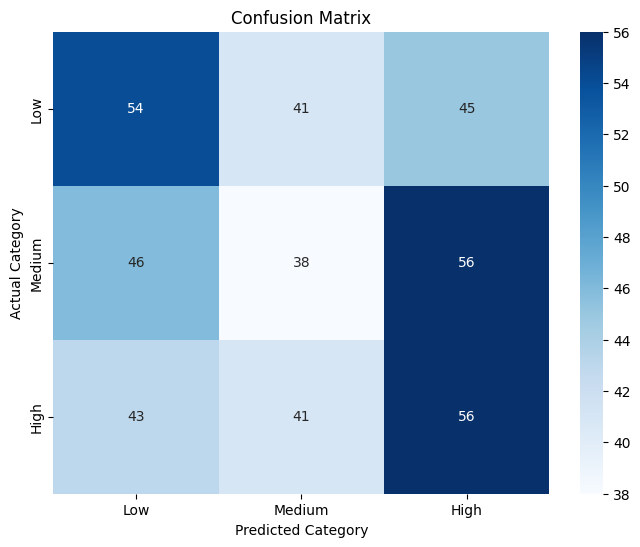


Feature Importance:


,Feature,Importance
0,size_mb,0.387581
4,time_minutes,0.271614
3,minute,0.211799
2,hour,0.129005
1,agent_count,0.000000


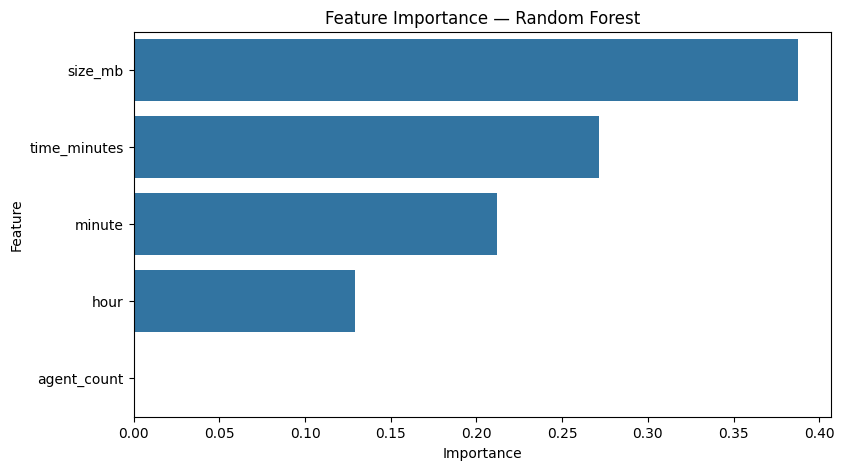


Predicted categories:


,episode_id,avg_score,score_category,predicted_category,prediction_probability
0,125582304,1434.586152,High,High,0.366527
1,125580441,1432.695200,High,Low,0.380505
2,125579531,1430.721092,High,High,0.413405
3,125583229,1429.310546,High,High,0.371937
4,125571078,1428.758842,High,Low,0.361869
5,125578592,1428.632226,High,High,0.362083
6,125573938,1428.009508,High,Low,0.350702
7,125572993,1428.009508,High,Low,0.372675
8,125572004,1426.105067,High,Low,0.413699
9,125575828,1426.081409,High,High,0.429883


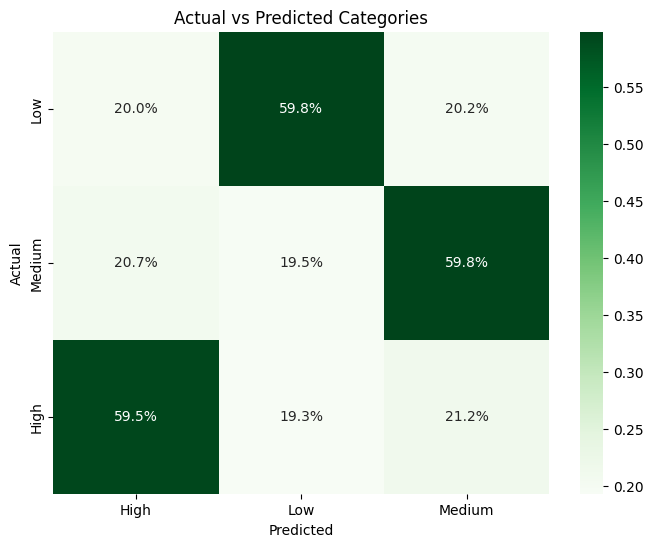


Analysis completed!
Saved: /content/pokemon_tcg_classification.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# POKEMON TCG — AUTOMATIC EPISODE CLASSIFICATION
# Machine Learning: Random Forest Classifier
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv('/content/manifest.csv')

df['create_time'] = pd.to_datetime(df['create_time'])

print("Dataset loaded:", df.shape)

# ============================================================
# 2. FEATURE ENGINEERING
# ============================================================

df['hour'] = df['create_time'].dt.hour
df['minute'] = df['create_time'].dt.minute
df['second'] = df['create_time'].dt.second

df['time_minutes'] = (
    df['hour'] * 60 +
    df['minute'] +
    df['second'] / 60
)

df['size_mb'] = df['size_bytes'] / (1024 ** 2)

# ============================================================
# 3. CREATE CLASSIFICATION TARGET
# ============================================================

# Divide episodes into 3 groups by avg_score:
# Low, Medium, High

df['score_category'] = pd.qcut(
    df['avg_score'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print("\nClass distribution:")
print(df['score_category'].value_counts())

# ============================================================
# 4. SELECT FEATURES
# ============================================================

# IMPORTANT:
# avg_score, min_score and sum_score are excluded
# to prevent target leakage.

features = [
    'size_mb',
    'agent_count',
    'hour',
    'minute',
    'time_minutes'
]

X = df[features]
y = df['score_category']

# ============================================================
# 5. SPLIT DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ============================================================
# 6. TRAIN BASELINE MODEL
# ============================================================

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

# ============================================================
# 7. TRAIN RANDOM FOREST
# ============================================================

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

# ============================================================
# 8. MAKE PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

print("\n" + "="*50)
print("MODEL PERFORMANCE")
print("="*50)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Random Forest Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

labels = ['Low', 'Medium', 'High']

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')

plt.show()

# ============================================================
# 10. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
display(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

# ============================================================
# 11. CLASSIFICATION OF ALL EPISODES
# ============================================================

df['predicted_category'] = model.predict(X)

df['prediction_probability'] = (
    model.predict_proba(X).max(axis=1)
)

print("\nPredicted categories:")

display(
    df[
        [
            'episode_id',
            'avg_score',
            'score_category',
            'predicted_category',
            'prediction_probability'
        ]
    ].head(20)
)

# ============================================================
# 12. COMPARE ACTUAL AND PREDICTED CLASSES
# ============================================================

comparison = pd.crosstab(
    df['score_category'],
    df['predicted_category'],
    normalize='index'
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt='.1%',
    cmap='Greens'
)

plt.title('Actual vs Predicted Categories')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

# ============================================================
# 13. SAVE RESULTS
# ============================================================

output_file = '/content/pokemon_tcg_classification.xlsx'

with pd.ExcelWriter(output_file) as writer:

    df.to_excel(
        writer,
        sheet_name='All Episodes',
        index=False
    )

    importance.to_excel(
        writer,
        sheet_name='Feature Importance',
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name='Class Comparison'
    )

    pd.DataFrame({
        'Metric': [
            'Baseline Accuracy',
            'Random Forest Accuracy',
            'Balanced Accuracy'
        ],
        'Value': [
            baseline_accuracy,
            accuracy,
            balanced_accuracy
        ]
    }).to_excel(
        writer,
        sheet_name='Model Metrics',
        index=False
    )

print("\nAnalysis completed!")
print("Saved:", output_file)

from google.colab import files
files.download(output_file)


In [ ]:

# ============================================================
# POKEMON TCG — INTELLIGENT ANOMALY DETECTION
# Algorithm: Isolation Forest
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid")

# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv('/content/manifest.csv')

df['create_time'] = pd.to_datetime(df['create_time'])

print("Dataset loaded successfully!")
print("Total episodes:", len(df))

# ============================================================
# 2. FEATURE ENGINEERING
# ============================================================

df['size_mb'] = df['size_bytes'] / (1024 ** 2)

df['score_gap'] = df['avg_score'] - df['min_score']

df['hour'] = df['create_time'].dt.hour

df['minute_of_day'] = (
    df['create_time'].dt.hour * 60 +
    df['create_time'].dt.minute
)

# ============================================================
# 3. SELECT FEATURES
# ============================================================

features = [
    'avg_score',
    'min_score',
    'score_gap',
    'size_mb',
    'hour',
    'minute_of_day'
]

X = df[features].copy()

# Проверка данных
if X.isnull().sum().sum() > 0:
    raise ValueError("Dataset contains missing values!")

# ============================================================
# 4. STANDARDIZE FEATURES
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ============================================================
# 5. TRAIN ISOLATION FOREST
# ============================================================

model = IsolationForest(
    n_estimators=300,
    max_samples='auto',
    contamination=0.05,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

model.fit(X_scaled)

print("\nAI model trained successfully!")

# ============================================================
# 6. DETECT ANOMALIES
# ============================================================

df['anomaly_prediction'] = model.predict(X_scaled)

# 1 = Normal
# -1 = Anomaly

df['anomaly_score'] = model.decision_function(X_scaled)

df['status'] = df['anomaly_prediction'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

# ============================================================
# 7. ANOMALY STATISTICS
# ============================================================

normal = df[df['status'] == 'Normal']

anomalies = df[df['status'] == 'Anomaly']

print("\n" + "=" * 50)
print("ANOMALY DETECTION RESULTS")
print("=" * 50)

print("Total episodes:", len(df))
print("Normal episodes:", len(normal))
print("Anomalies:", len(anomalies))

print(
    "Anomaly percentage:",
    round(len(anomalies) / len(df) * 100, 2),
    "%"
)

# ============================================================
# 8. MOST UNUSUAL EPISODES
# ============================================================

top_anomalies = anomalies.sort_values(
    by='anomaly_score',
    ascending=True
).head(30)

print("\nTOP 30 MOST UNUSUAL EPISODES")

display(
    top_anomalies[
        [
            'episode_id',
            'create_time',
            'avg_score',
            'min_score',
            'score_gap',
            'size_mb',
            'hour',
            'anomaly_score'
        ]
    ].round(3)
)

# ============================================================
# 9. COMPARE NORMAL AND ANOMALOUS EPISODES
# ============================================================

comparison = df.groupby('status')[
    [
        'avg_score',
        'min_score',
        'score_gap',
        'size_mb'
    ]
].agg(['mean', 'median', 'std'])

print("\nNORMAL VS ANOMALOUS EPISODES")

display(comparison.round(2))

# ============================================================
# 10. VISUALIZATION 1 — SCORE AND FILE SIZE
# ============================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='size_mb',
    y='avg_score',
    hue='status',
    palette={
        'Normal': 'steelblue',
        'Anomaly': 'red'
    },
    alpha=0.7,
    s=65
)

plt.title('AI Anomaly Detection: Pokémon TCG Episodes')
plt.xlabel('Episode Size (MB)')
plt.ylabel('Average Score')

plt.show()

# ============================================================
# 11. VISUALIZATION 2 — ANOMALY SCORE
# ============================================================

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x='anomaly_score',
    hue='status',
    bins=40,
    element='step',
    stat='count'
)

plt.title('Distribution of Anomaly Scores')
plt.xlabel('Anomaly Score')
plt.show()

# Lower scores = more unusual episodes

# ============================================================
# 12. VISUALIZATION 3 — SCORE GAP
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='status',
    y='score_gap'
)

plt.title('Score Gap: Normal vs Anomalies')
plt.show()

# ============================================================
# 13. VISUALIZATION 4 — EPISODES OVER TIME
# ============================================================

plt.figure(figsize=(13, 6))

sns.scatterplot(
    data=df,
    x='create_time',
    y='avg_score',
    hue='status',
    palette={
        'Normal': 'steelblue',
        'Anomaly': 'red'
    },
    alpha=0.7
)

plt.title('Anomalies Over Time')
plt.xlabel('Creation Time')
plt.ylabel('Average Score')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# 14. FEATURE IMPORTANCE APPROXIMATION
# ============================================================

# Permutation importance is not used here:
# Isolation Forest does not have native feature importance.
# Instead, compare the distributions of each feature.

for feature in features:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=df,
        x='status',
        y=feature,
        hue='status',
        legend=False
    )

    plt.title(f'{feature}: Normal vs Anomaly')
    plt.tight_layout()
    plt.show()

# ============================================================
# 15. SAVE RESULTS
# ============================================================

output_file = '/content/pokemon_tcg_anomaly_results.xlsx'

with pd.ExcelWriter(output_file) as writer:

    df.to_excel(
        writer,
        sheet_name='All Episodes',
        index=False
    )

    top_anomalies.to_excel(
        writer,
        sheet_name='Top 30 Anomalies',
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name='Comparison'
    )

print("\nAnalysis completed!")
print("Results saved:", output_file)

from google.colab import files

files.download(output_file)


FileNotFoundError: [Errno 2] No such file or directory: '/content/manifest.csv'

In [ ]:

# ============================================================
# POKEMON TCG — TEMPORAL ANALYSIS
# Google Colab | Input: /content/manifest.csv
# ============================================================

!pip -q install openpyxl scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import mannwhitneyu, kruskal, spearmanr, kendalltau
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. НАСТРОЙКИ
# ------------------------------------------------------------

FILE_PATH = "/content/manifest.csv"
OUTPUT_DIR = "/content/pokemon_time_analysis"

ROLLING_WINDOW = 30       # Скользящее окно в количестве эпизодов
TIME_BIN = "30min"        # Интервал группировки по времени
MIN_GROUP_SIZE = 3        # Минимум наблюдений для статистических групп

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 65)
print("POKEMON TCG — TEMPORAL RESEARCH")
print("=" * 65)

# ------------------------------------------------------------
# 2. ЗАГРУЗКА ДАННЫХ
# ------------------------------------------------------------

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(f"Файл не найден: {FILE_PATH}")

df = pd.read_csv(FILE_PATH)

print(f"\nЗагружено строк: {len(df)}")
print("Столбцы:", list(df.columns))

required_columns = ["create_time", "avg_score"]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Отсутствуют обязательные столбцы: {missing_columns}")

# Преобразуем числовые показатели
numeric_columns = [
    "avg_score", "min_score", "sum_score",
    "agent_count", "size_bytes"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------------------
# 3. ОБРАБОТКА ДАТЫ И ВРЕМЕНИ
# ------------------------------------------------------------

def parse_datetime(series):
    """
    Поддерживает:
    - обычные даты и время;
    - Unix timestamp в секундах;
    - Unix timestamp в миллисекундах;
    - Unix timestamp в микросекундах;
    - Unix timestamp в наносекундах.
    """

    numeric = pd.to_numeric(series, errors="coerce")
    numeric_ratio = numeric.notna().mean()

    if numeric_ratio > 0.8:
        median_value = numeric.dropna().abs().median()

        if median_value > 1e17:
            unit = "ns"
        elif median_value > 1e14:
            unit = "us"
        elif median_value > 1e11:
            unit = "ms"
        else:
            unit = "s"

        return pd.to_datetime(
            numeric, unit=unit, errors="coerce", utc=True
        ).dt.tz_convert(None)

    return pd.to_datetime(series, errors="coerce", utc=True).dt.tz_convert(None)


df["datetime"] = parse_datetime(df["create_time"])

# Удаляем строки без даты или оценки
df = df.dropna(subset=["datetime", "avg_score"]).copy()

if len(df) < 10:
    raise ValueError("После очистки осталось меньше 10 эпизодов.")

df = df.sort_values(["datetime"]).reset_index(drop=True)

# Временные признаки
df["date"] = df["datetime"].dt.date
df["hour"] = df["datetime"].dt.hour
df["minute"] = df["datetime"].dt.minute
df["minute_of_day"] = df["hour"] * 60 + df["minute"]
df["elapsed_minutes"] = (
    df["datetime"] - df["datetime"].min()
).dt.total_seconds() / 60

df["episode_order"] = np.arange(1, len(df) + 1)

# Размер файлов в MB
if "size_bytes" in df.columns:
    df["size_mb"] = df["size_bytes"] / (1024 ** 2)

# Разница между средним и минимальным результатом
if "min_score" in df.columns:
    df["score_gap"] = df["avg_score"] - df["min_score"]

    df["score_gap_percent"] = np.where(
        df["avg_score"] != 0,
        df["score_gap"] / df["avg_score"] * 100,
        np.nan
    )

print("\nПериод наблюдения:")
print("Начало:", df["datetime"].min())
print("Конец: ", df["datetime"].max())
print("Эпизодов после очистки:", len(df))
print("Уникальных дней:", df["date"].nunique())

# ------------------------------------------------------------
# 4. ОБЩАЯ СТАТИСТИКА
# ------------------------------------------------------------

numeric_for_stats = [
    c for c in [
        "avg_score", "min_score", "sum_score",
        "size_mb", "score_gap", "score_gap_percent"
    ] if c in df.columns
]

general_stats = df[numeric_for_stats].describe().T

general_stats["median"] = df[numeric_for_stats].median()
general_stats["variance"] = df[numeric_for_stats].var()
general_stats["skewness"] = df[numeric_for_stats].skew()

general_stats["coefficient_of_variation_%"] = (
    df[numeric_for_stats].std() /
    df[numeric_for_stats].mean().replace(0, np.nan) * 100
)

print("\nОБЩАЯ СТАТИСТИКА")
display(general_stats.round(3))

# ------------------------------------------------------------
# 5. АНАЛИЗ РЕЗУЛЬТАТОВ ПО ЧАСАМ
# ------------------------------------------------------------

hourly = (
    df.groupby("hour")
    .agg(
        episode_count=("avg_score", "count"),
        avg_score=("avg_score", "mean"),
        median_score=("avg_score", "median"),
        std_score=("avg_score", "std"),
        min_score=("avg_score", "min"),
        max_score=("avg_score", "max"),
        avg_size_mb=("size_mb", "mean") if "size_mb" in df.columns
        else ("avg_score", "mean")
    )
    .reset_index()
)

hourly["cv_percent"] = (
    hourly["std_score"] / hourly["avg_score"] * 100
)

hourly["score_range"] = hourly["max_score"] - hourly["min_score"]

print("\nРЕЗУЛЬТАТЫ ПО ЧАСАМ")
display(hourly.round(3))

# ------------------------------------------------------------
# 6. АНАЛИЗ ПО 30-МИНУТНЫМ ИНТЕРВАЛАМ
# ------------------------------------------------------------

time_df = df.set_index("datetime")

time_bins = (
    time_df.resample(TIME_BIN)
    .agg(
        episode_count=("avg_score", "count"),
        avg_score=("avg_score", "mean"),
        median_score=("avg_score", "median"),
        std_score=("avg_score", "std"),
        min_score=("avg_score", "min"),
        max_score=("avg_score", "max")
    )
    .dropna(subset=["avg_score"])
    .reset_index()
)

time_bins["score_range"] = (
    time_bins["max_score"] - time_bins["min_score"]
)

print("\nРЕЗУЛЬТАТЫ ПО ВРЕМЕННЫМ ИНТЕРВАЛАМ")
display(time_bins.head(20).round(3))

# ------------------------------------------------------------
# 7. СКОЛЬЗЯЩЕЕ СРЕДНЕЕ И ВОЛАТИЛЬНОСТЬ
# ------------------------------------------------------------

df["rolling_mean"] = (
    df["avg_score"].rolling(
        window=ROLLING_WINDOW,
        min_periods=max(5, ROLLING_WINDOW // 3)
    ).mean()
)

df["rolling_std"] = (
    df["avg_score"].rolling(
        window=ROLLING_WINDOW,
        min_periods=max(5, ROLLING_WINDOW // 3)
    ).std()
)

df["rolling_cv_percent"] = (
    df["rolling_std"] / df["rolling_mean"] * 100
)

df["score_change"] = df["avg_score"].diff()

df["absolute_score_change"] = df["score_change"].abs()

# ------------------------------------------------------------
# 8. ТРЕНД: УЛУЧШАЛИСЬ ИЛИ УХУДШАЛИСЬ РЕЗУЛЬТАТЫ?
# ------------------------------------------------------------

x = df["elapsed_minutes"].to_numpy()
y = df["avg_score"].to_numpy()

linear_result = stats.linregress(x, y)

trend_slope = linear_result.slope
trend_pvalue = linear_result.pvalue
trend_r2 = linear_result.rvalue ** 2

spearman_r, spearman_p = spearmanr(x, y)
kendall_r, kendall_p = kendalltau(x, y)

trend_summary = pd.DataFrame([
    ["Linear slope (points/min)", trend_slope],
    ["Linear slope (points/hour)", trend_slope * 60],
    ["R-squared", trend_r2],
    ["Linear trend p-value", trend_pvalue],
    ["Spearman correlation", spearman_r],
    ["Spearman p-value", spearman_p],
    ["Kendall correlation", kendall_r],
    ["Kendall p-value", kendall_p]
], columns=["metric", "value"])

print("\nАНАЛИЗ ТРЕНДА")
display(trend_summary.round(6))

# ------------------------------------------------------------
# 9. СРАВНЕНИЕ ПЕРВОЙ И ВТОРОЙ ПОЛОВИНЫ ДНЯ
# ------------------------------------------------------------

middle_time = df["datetime"].min() + (
    df["datetime"].max() - df["datetime"].min()
) / 2

df["period_half"] = np.where(
    df["datetime"] <= middle_time,
    "First half",
    "Second half"
)

first_half = df.loc[
    df["period_half"] == "First half", "avg_score"
].dropna()

second_half = df.loc[
    df["period_half"] == "Second half", "avg_score"
].dropna()

half_comparison = df.groupby("period_half")["avg_score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

if len(first_half) >= 2 and len(second_half) >= 2:
    half_test = mannwhitneyu(
        first_half, second_half, alternative="two-sided"
    )
    half_pvalue = half_test.pvalue
else:
    half_pvalue = np.nan

print("\nСРАВНЕНИЕ ПЕРВОЙ И ВТОРОЙ ПОЛОВИНЫ")
display(half_comparison.round(3))
print("Mann-Whitney p-value:", half_pvalue)

# ------------------------------------------------------------
# 10. СТАТИСТИЧЕСКАЯ ПРОВЕРКА РАЗЛИЧИЙ МЕЖДУ ЧАСАМИ
# ------------------------------------------------------------

hour_groups = [
    group["avg_score"].values
    for _, group in df.groupby("hour")
    if len(group) >= MIN_GROUP_SIZE
]

if len(hour_groups) >= 2:
    hour_test = kruskal(*hour_groups)
    hour_pvalue = hour_test.pvalue
    hour_statistic = hour_test.statistic
else:
    hour_pvalue = np.nan
    hour_statistic = np.nan

hour_test_results = pd.DataFrame({
    "metric": ["Kruskal-Wallis statistic", "p-value"],
    "value": [hour_statistic, hour_pvalue]
})

print("\nРАЗЛИЧИЯ МЕЖДУ ЧАСАМИ")
display(hour_test_results.round(6))

# ------------------------------------------------------------
# 11. АВТОКОРРЕЛЯЦИЯ
# ------------------------------------------------------------

def calculate_autocorrelation(series, max_lag=20):
    values = np.asarray(series.dropna(), dtype=float)
    values = values - np.mean(values)

    max_lag = min(max_lag, len(values) - 2)
    result = []

    for lag in range(1, max_lag + 1):
        if np.std(values[:-lag]) == 0 or np.std(values[lag:]) == 0:
            corr = np.nan
        else:
            corr = np.corrcoef(
                values[:-lag], values[lag:]
            )[0, 1]

        result.append([lag, corr])

    return pd.DataFrame(
        result, columns=["lag", "autocorrelation"]
    )

autocorrelation = calculate_autocorrelation(
    df["avg_score"], max_lag=20
)

autocorrelation["approx_significance_limit"] = (
    1.96 / np.sqrt(len(df))
)

print("\nАВТОКОРРЕЛЯЦИЯ")
display(autocorrelation.round(4))

# ------------------------------------------------------------
# 12. ПОИСК РЕЗКИХ ИЗМЕНЕНИЙ
# ------------------------------------------------------------

# Используем стандартизированные изменения соседних результатов.
change_std = df["score_change"].std()

if pd.notna(change_std) and change_std > 0:
    df["change_zscore"] = (
        df["score_change"] - df["score_change"].mean()
    ) / change_std
else:
    df["change_zscore"] = np.nan

df["large_change"] = (
    df["change_zscore"].abs() >= 3
)

# Дополнительный поиск локальных выбросов:
# медиана и MAD в скользящем окне.

rolling_median = df["avg_score"].rolling(
    window=ROLLING_WINDOW,
    min_periods=max(5, ROLLING_WINDOW // 3),
    center=True
).median()

absolute_deviation = (df["avg_score"] - rolling_median).abs()

rolling_mad = absolute_deviation.rolling(
    window=ROLLING_WINDOW,
    min_periods=max(5, ROLLING_WINDOW // 3),
    center=True
).median()

df["local_robust_z"] = (
    0.6745 * (df["avg_score"] - rolling_median) /
    rolling_mad.replace(0, np.nan)
)

df["local_anomaly"] = (
    df["local_robust_z"].abs() >= 3.5
)

large_changes = df[df["large_change"]].copy()
local_anomalies = df[df["local_anomaly"]].copy()

print("\nРЕЗКИЕ ИЗМЕНЕНИЯ МЕЖДУ СОСЕДНИМИ ЭПИЗОДАМИ")
display(
    large_changes[
        ["datetime", "episode_order", "avg_score",
         "score_change", "change_zscore"]
    ].round(3).head(30)
)

print("\nЛОКАЛЬНЫЕ АНОМАЛИИ")
display(
    local_anomalies[
        ["datetime", "episode_order", "avg_score",
         "local_robust_z"]
    ].round(3).head(30)
)

# ------------------------------------------------------------
# 13. КОРРЕЛЯЦИЯ ВРЕМЕНИ С ДРУГИМИ ПОКАЗАТЕЛЯМИ
# ------------------------------------------------------------

correlation_rows = []

for col in ["avg_score", "min_score", "size_mb", "score_gap"]:
    if col not in df.columns:
        continue

    temp = df[["elapsed_minutes", col]].dropna()

    if len(temp) >= 3:
        pearson_r, pearson_p = stats.pearsonr(
            temp["elapsed_minutes"], temp[col]
        )

        spearman_value, spearman_p_value = spearmanr(
            temp["elapsed_minutes"], temp[col]
        )

        correlation_rows.append([
            col, pearson_r, pearson_p,
            spearman_value, spearman_p_value
        ])

time_correlations = pd.DataFrame(
    correlation_rows,
    columns=[
        "variable",
        "pearson_r",
        "pearson_p",
        "spearman_r",
        "spearman_p"
    ]
)

print("\nКОРРЕЛЯЦИЯ ПОКАЗАТЕЛЕЙ СО ВРЕМЕНЕМ")
display(time_correlations.round(5))

# ------------------------------------------------------------
# 14. ЦИКЛИЧЕСКИЕ ПРИЗНАКИ ВРЕМЕНИ
# ------------------------------------------------------------

# Время суток циклическое:
# 23:59 близко к 00:00, а не далеко от него.

df["time_sin"] = np.sin(
    2 * np.pi * df["minute_of_day"] / 1440
)

df["time_cos"] = np.cos(
    2 * np.pi * df["minute_of_day"] / 1440
)

# Проверяем связь времени суток с результатом
if df["time_sin"].nunique() > 1 and df["time_cos"].nunique() > 1:
    cyclic_sin_r, cyclic_sin_p = spearmanr(
        df["time_sin"], df["avg_score"]
    )
    cyclic_cos_r, cyclic_cos_p = spearmanr(
        df["time_cos"], df["avg_score"]
    )
else:
    cyclic_sin_r = cyclic_sin_p = np.nan
    cyclic_cos_r = cyclic_cos_p = np.nan

cyclic_results = pd.DataFrame([
    ["time_sin", cyclic_sin_r, cyclic_sin_p],
    ["time_cos", cyclic_cos_r, cyclic_cos_p]
], columns=["feature", "spearman_r", "p_value"])

print("\nЦИКЛИЧЕСКИЕ ВРЕМЕННЫЕ ПРИЗНАКИ")
display(cyclic_results.round(5))

# ------------------------------------------------------------
# 15. ГРАФИКИ
# ------------------------------------------------------------

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True

def save_plot(filename):
    path = os.path.join(OUTPUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

# График 1. Результаты во времени
plt.figure()
plt.scatter(
    df["datetime"], df["avg_score"], alpha=0.45,
    label="Individual episodes"
)

plt.plot(
    df["datetime"], df["rolling_mean"],
    linewidth=2, label=f"Rolling mean ({ROLLING_WINDOW})"
)

plt.title("Average score over time")
plt.xlabel("Time")
plt.ylabel("Average score")
plt.xticks(rotation=30)
plt.legend()
save_plot("01_score_over_time.png")

# График 2. Линейный тренд
plt.figure()

plt.scatter(
    df["elapsed_minutes"], df["avg_score"],
    alpha=0.4, label="Episodes"
)

trend_line = (
    linear_result.intercept + trend_slope * x
)

plt.plot(
    x, trend_line, linewidth=2,
    label="Linear trend"
)

plt.title("Score trend during the observation period")
plt.xlabel("Elapsed minutes")
plt.ylabel("Average score")
plt.legend()
save_plot("02_linear_trend.png")

# График 3. Средний результат по часам
plt.figure()

plt.bar(
    hourly["hour"].astype(str),
    hourly["avg_score"]
)

plt.title("Average score by hour")
plt.xlabel("Hour of day")
plt.ylabel("Average score")
save_plot("03_hourly_average.png")

# График 4. Количество эпизодов по часам
plt.figure()

plt.bar(
    hourly["hour"].astype(str),
    hourly["episode_count"]
)

plt.title("Episode count by hour")
plt.xlabel("Hour of day")
plt.ylabel("Number of episodes")
save_plot("04_hourly_episode_count.png")

# График 5. Волатильность по времени
plt.figure()

plt.plot(
    df["datetime"], df["rolling_std"],
    linewidth=2
)

plt.title(f"Rolling score volatility ({ROLLING_WINDOW} episodes)")
plt.xlabel("Time")
plt.ylabel("Rolling standard deviation")
plt.xticks(rotation=30)
save_plot("05_rolling_volatility.png")

# График 6. Изменения между соседними эпизодами
plt.figure()

plt.plot(
    df["datetime"], df["score_change"],
    alpha=0.65
)

plt.axhline(0, linewidth=1)
plt.axhline(3 * change_std, linestyle="--")
plt.axhline(-3 * change_std, linestyle="--")

plt.title("Score changes between consecutive episodes")
plt.xlabel("Time")
plt.ylabel("Change in average score")
plt.xticks(rotation=30)
save_plot("06_score_changes.png")

# График 7. Автокорреляция
plt.figure()

plt.bar(
    autocorrelation["lag"].astype(str),
    autocorrelation["autocorrelation"]
)

plt.axhline(
    1.96 / np.sqrt(len(df)),
    linestyle="--", label="Approx. significance limit"
)

plt.axhline(
    -1.96 / np.sqrt(len(df)),
    linestyle="--"
)

plt.title("Autocorrelation of average scores")
plt.xlabel("Lag (number of episodes)")
plt.ylabel("Correlation")
plt.legend()
save_plot("07_autocorrelation.png")

# График 8. Результаты по 30-минутным интервалам
plt.figure()

plt.plot(
    time_bins["datetime"],
    time_bins["avg_score"],
    marker="o"
)

plt.title(f"Average score in {TIME_BIN} intervals")
plt.xlabel("Time")
plt.ylabel("Average score")
plt.xticks(rotation=30)
save_plot("08_time_bins.png")

# График 9. Локальные аномалии
plt.figure()

plt.plot(
    df["datetime"], df["avg_score"],
    alpha=0.5, label="All episodes"
)

if len(local_anomalies) > 0:
    plt.scatter(
        local_anomalies["datetime"],
        local_anomalies["avg_score"],
        marker="x", s=80,
        label="Local anomalies"
    )

plt.title("Local score anomalies over time")
plt.xlabel("Time")
plt.ylabel("Average score")
plt.xticks(rotation=30)
plt.legend()
save_plot("09_local_anomalies.png")

# График 10. Размер файла и время
if "size_mb" in df.columns:
    plt.figure()

    plt.scatter(
        df["datetime"], df["size_mb"], alpha=0.5
    )

    plt.title("Episode file size over time")
    plt.xlabel("Time")
    plt.ylabel("File size (MB)")
    plt.xticks(rotation=30)
    save_plot("10_file_size_over_time.png")

# ------------------------------------------------------------
# 16. АВТОМАТИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ
# ------------------------------------------------------------

interpretations = []

def add_interpretation(title, text):
    interpretations.append({
        "topic": title,
        "interpretation": text
    })

# Тренд
if trend_pvalue < 0.05:
    if trend_slope > 0:
        add_interpretation(
            "Overall trend",
            f"Обнаружен статистически значимый положительный линейный тренд: "
            f"+{trend_slope * 60:.3f} балла в час. "
            "Это ассоциация со временем, а не доказательство причины."
        )
    else:
        add_interpretation(
            "Overall trend",
            f"Обнаружен статистически значимый отрицательный линейный тренд: "
            f"{trend_slope * 60:.3f} балла в час. "
            "Это ассоциация со временем, а не доказательство причины."
        )
else:
    add_interpretation(
        "Overall trend",
        "Статистически значимый линейный тренд не обнаружен. "
        "Это не исключает нелинейные изменения."
    )

# Половины
if pd.notna(half_pvalue):
    difference = second_half.mean() - first_half.mean()

    if half_pvalue < 0.05:
        add_interpretation(
            "First half vs second half",
            f"Разница между половинами статистически значима "
            f"(p={half_pvalue:.4g}). "
            f"Среднее второй половины отличается на {difference:.3f} балла."
        )
    else:
        add_interpretation(
            "First half vs second half",
            f"Статистически значимой разницы между половинами не найдено "
            f"(p={half_pvalue:.4g})."
        )

# Различия между часами
if pd.notna(hour_pvalue):
    if hour_pvalue < 0.05:
        add_interpretation(
            "Hourly differences",
            f"Есть статистические свидетельства различий между часовыми "
            f"группами (Kruskal-Wallis p={hour_pvalue:.4g})."
        )
    else:
        add_interpretation(
            "Hourly differences",
            f"Статистически значимые различия между часовыми группами "
            f"не обнаружены (p={hour_pvalue:.4g})."
        )

# Автокорреляция
if len(autocorrelation):
    strongest = autocorrelation.loc[
        autocorrelation["autocorrelation"].abs().idxmax()
    ]

    add_interpretation(
        "Autocorrelation",
        f"Наибольшая по модулю автокорреляция наблюдается на лаге "
        f"{int(strongest['lag'])}: "
        f"{strongest['autocorrelation']:.3f}. "
        "Это может указывать на зависимость соседних эпизодов."
    )

# Аномалии
add_interpretation(
    "Local anomalies",
    f"Найдено {len(local_anomalies)} локальных необычных эпизодов "
    f"по робастному отклонению от локальной медианы."
)

add_interpretation(
    "Large consecutive changes",
    f"Найдено {len(large_changes)} эпизодов с изменением результата "
    "между соседними эпизодами более чем на 3 стандартных отклонения."
)

# Самый высокий и низкий час
best_hour = hourly.loc[hourly["avg_score"].idxmax()]
worst_hour = hourly.loc[hourly["avg_score"].idxmin()]

add_interpretation(
    "Best observed hour",
    f"Самое высокое среднее значение наблюдалось в {int(best_hour['hour']):02d}:00 "
    f"({best_hour['avg_score']:.3f}; эпизодов: {int(best_hour['episode_count'])})."
)

add_interpretation(
    "Lowest observed hour",
    f"Самое низкое среднее значение наблюдалось в {int(worst_hour['hour']):02d}:00 "
    f"({worst_hour['avg_score']:.3f}; эпизодов: {int(worst_hour['episode_count'])})."
)

interpretation_df = pd.DataFrame(interpretations)

print("\n" + "=" * 65)
print("АВТОМАТИЧЕСКИЕ ВЫВОДЫ")
print("=" * 65)

for item in interpretations:
    print(f"\n{item['topic']}:")
    print(item["interpretation"])

# ------------------------------------------------------------
# 17. СВОДНАЯ ТАБЛИЦА КЛЮЧЕВЫХ РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

summary = pd.DataFrame([
    ["Episodes analyzed", len(df)],
    ["Observation start", str(df["datetime"].min())],
    ["Observation end", str(df["datetime"].max())],
    ["Observation duration (hours)",
     (df["datetime"].max() - df["datetime"].min()).total_seconds() / 3600],
    ["Overall average score", df["avg_score"].mean()],
    ["Overall median score", df["avg_score"].median()],
    ["Overall score std", df["avg_score"].std()],
    ["Linear trend (points/hour)", trend_slope * 60],
    ["Linear trend p-value", trend_pvalue],
    ["Linear trend R-squared", trend_r2],
    ["Spearman time correlation", spearman_r],
    ["First/second half p-value", half_pvalue],
    ["Hourly Kruskal-Wallis p-value", hour_pvalue],
    ["Local anomalies", len(local_anomalies)],
    ["Large consecutive changes", len(large_changes)],
    ["Best hour", int(best_hour["hour"])],
    ["Worst hour", int(worst_hour["hour"])]
], columns=["metric", "value"])

print("\nИТОГОВАЯ СВОДКА")
display(summary)

# ------------------------------------------------------------
# 18. ЭКСПОРТ В EXCEL
# ------------------------------------------------------------

excel_path = os.path.join(
    OUTPUT_DIR, "pokemon_temporal_analysis.xlsx"
)

# Сохраняем дополнительные листы
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    summary.to_excel(
        writer, sheet_name="Summary", index=False
    )

    general_stats.to_excel(
        writer, sheet_name="General Statistics"
    )

    hourly.to_excel(
        writer, sheet_name="Hourly Analysis", index=False
    )

    time_bins.to_excel(
        writer, sheet_name="Time Intervals", index=False
    )

    trend_summary.to_excel(
        writer, sheet_name="Trend", index=False
    )

    half_comparison.to_excel(
        writer, sheet_name="Half Comparison"
    )

    hour_test_results.to_excel(
        writer, sheet_name="Hourly Test", index=False
    )

    autocorrelation.to_excel(
        writer, sheet_name="Autocorrelation", index=False
    )

    time_correlations.to_excel(
        writer, sheet_name="Time Correlations", index=False
    )

    cyclic_results.to_excel(
        writer, sheet_name="Cyclic Features", index=False
    )

    interpretation_df.to_excel(
        writer, sheet_name="Interpretation", index=False
    )

    df.to_excel(
        writer, sheet_name="All Episodes", index=False
    )

    large_changes.to_excel(
        writer, sheet_name="Large Changes", index=False
    )

    local_anomalies.to_excel(
        writer, sheet_name="Local Anomalies", index=False
    )

print("\nExcel сохранён:", excel_path)

# ------------------------------------------------------------
# 19. СОХРАНЕНИЕ CSV И ГРАФИКОВ
# ------------------------------------------------------------

df.to_csv(
    os.path.join(OUTPUT_DIR, "all_episodes.csv"),
    index=False
)

hourly.to_csv(
    os.path.join(OUTPUT_DIR, "hourly_analysis.csv"),
    index=False
)

time_bins.to_csv(
    os.path.join(OUTPUT_DIR, "time_intervals.csv"),
    index=False
)

interpretation_df.to_csv(
    os.path.join(OUTPUT_DIR, "interpretation.csv"),
    index=False
)

# ------------------------------------------------------------
# 20. АРХИВ ВСЕГО ИССЛЕДОВАНИЯ
# ------------------------------------------------------------

import shutil

archive_path = shutil.make_archive(
    "/content/pokemon_temporal_analysis",
    "zip",
    OUTPUT_DIR
)

print("\n" + "=" * 65)
print("ИССЛЕДОВАНИЕ ЗАВЕРШЕНО")
print("=" * 65)

print("\nСозданы файлы:")
print("Excel:", excel_path)
print("ZIP:", archive_path)
print("Папка с графиками и CSV:", OUTPUT_DIR)

# Ссылки для скачивания в Google Colab
try:
    from google.colab import files

    print("\nНачинается скачивание Excel...")
    files.download(excel_path)

    print("\nНачинается скачивание архива...")
    files.download(archive_path)

except ImportError:
    print("Среда не Colab. Файлы сохранены в OUTPUT_DIR.")

# ------------------------------------------------------------
# 21. ФИНАЛЬНЫЙ КРАТКИЙ ОТЧЁТ
# ------------------------------------------------------------

display(Markdown("## Итог исследования"))

print(f"""
Проанализировано эпизодов: {len(df)}

Средняя оценка: {df['avg_score'].mean():.3f}
Медианная оценка: {df['avg_score'].median():.3f}

Линейный тренд:
{trend_slope * 60:+.3f} балла в час

R² линейной модели:
{trend_r2:.4f}

p-value тренда:
{trend_pvalue:.6f}

Локальных аномалий:
{len(local_anomalies)}

Резких изменений между соседними эпизодами:
{len(large_changes)}

Самый высокий средний результат по часам:
{int(best_hour['hour']):02d}:00

Самый низкий средний результат по часам:
{int(worst_hour['hour']):02d}:00
""")

print("Исследование завершено успешно.")


POKEMON TCG — TEMPORAL RESEARCH


FileNotFoundError: Файл не найден: /content/manifest.csv